# Dự án: Phân tích chất lượng không khí Hà Nội

# Phần 2: Phân tích khám phá dữ liệu

# I. Import thư viện

In [1]:
import requests
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import datetime
import seaborn as sns
import plotly.express as px

pd.set_option("display.max_columns", None)


# II. Đọc dữ liệu

In [2]:
# Đọc file CSV vào DataFrame
df = pd.read_csv('Data/hanoi-aqi-weather-data.csv')

# Chuyen cot 'Local Time' sang kieu datetime
df['Local Time'] = pd.to_datetime(
        df['Local Time'],
        errors='coerce')
# errors='coerce' se chuyen nhung gia tri khong hop le sang NaT (Not a Time)


print("Số giá trị thời gian không đọc được:",
      df["Local Time"].isna().sum())

df = df.sort_values("Local Time")
df = df.set_index("Local Time", inplace=False)

print("Thời gian bắt đầu:", df.index.min())
print("Thời gian kết thúc:", df.index.max())
print("Thời gian tăng dần:",
      df.index.is_monotonic_increasing)

# Hien thi DataFrame
df.head()


Số giá trị thời gian không đọc được: 0
Thời gian bắt đầu: 2023-03-08 00:00:00
Thời gian kết thúc: 2024-03-08 00:00:00
Thời gian tăng dần: True


,UTC Time,City,Country Code,Timezone,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
Local Time,,,,,,,,,,,,,,,,,,
2023-03-08 00:00:00,2023-03-07T17:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,131,170.6,29.3,53.3,58.8,47.0,67.3,91,0.0,1016,86,21.2,0.0,2.00
2023-03-08 01:00:00,2023-03-07T18:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,158.7,25.0,54.0,56.3,45.0,65.0,100,0.0,1016,89,21.1,0.0,2.00
2023-03-08 02:00:00,2023-03-07T19:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,150.2,21.7,55.0,52.5,42.0,65.7,100,0.0,1016,90,20.9,0.0,1.66
2023-03-08 03:00:00,2023-03-07T20:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,126,141.6,18.3,56.0,56.3,45.0,66.3,100,0.0,1016,91,20.7,0.0,1.33
2023-03-08 04:00:00,2023-03-07T21:00:00,Hanoi,VN,Asia/Ho_Chi_Minh,118,133.1,15.0,57.0,52.5,42.0,67.0,100,0.0,1015,92,20.5,0.0,1.00


In [3]:
print("Số dòng:", df.shape[0])
print("Số cột:", df.shape[1])
print("Tên cột:")
print(df.columns.tolist())

Số dòng: 8785
Số cột: 18
Tên cột:
['UTC Time', 'City', 'Country Code', 'Timezone', 'AQI', 'CO', 'NO2', 'O3', 'PM10', 'PM25', 'SO2', 'Clouds', 'Precipitation', 'Pressure', 'Relative Humidity', 'Temperature', 'UV Index', 'Wind Speed']


## 1. Kiểm tra timestamp trùng

In [4]:
print("So timestamp trung: ",df.index.duplicated().sum())
df[df.index.duplicated(keep=False)].head(10)


# Neu co timestamp trung 
# Lay trung binh tat ca cot so trong cung 1 gio
df = df.groupby(level = 0).mean(numeric_only=True)



So timestamp trung:  0


## 2. Tìm giờ bị thiếu

In [5]:
hourly_index = pd.date_range(
    start = df.index.min(),
    end = df.index.max(),
    freq = 'h'
)

# freq = 'h' tao một mốc thời gian cách nhau 1 giờ

missing_timestamps = hourly_index.difference(df.index)



print("Tong so gio: ", len(hourly_index))
print("Tong so gio thieu: ", len(missing_timestamps))

missing_timestamps[:20]

# Xem dữ liệu thiếu tập trung theo tháng

# Tao DataFrame chua timestamp bi thieu
missing_info = pd.DataFrame({
    "timestamp": missing_timestamps,
})

# .dt thuoc tinh xu ly ngay gio cua Pandas
missing_info["month"] = (
    missing_info["timestamp"]
    .dt.to_period("M") # chuyen timestamp -> thang
    .astype(str)  # chuyen Period thanh chuoi String 
)

print(missing_info["month"].value_counts().sort_index())

# Tao lai timeline
df = df.reindex(hourly_index)
df.index.name = "Local Time"


Tong so gio:  8785
Tong so gio thieu:  0
Series([], Name: count, dtype: int64)


# III. Chuẩn bị dữ liệu

In [6]:
missing_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
}).sort_values("missing_count", ascending=False)

missing_summary

,missing_count,missing_percent
AQI,0,0.0
CO,0,0.0
NO2,0,0.0
O3,0,0.0
PM10,0,0.0
PM25,0,0.0
SO2,0,0.0
Clouds,0,0.0
Precipitation,0,0.0
Pressure,0,0.0


In [7]:
missing_by_month = df.isna().resample("MS").mean() * 100
missing_by_month.round(2)

,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed
Local Time,,,,,,,,,,,,,,
2023-03-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-04-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-05-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-06-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-07-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-08-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-09-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-10-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2023-11-01,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


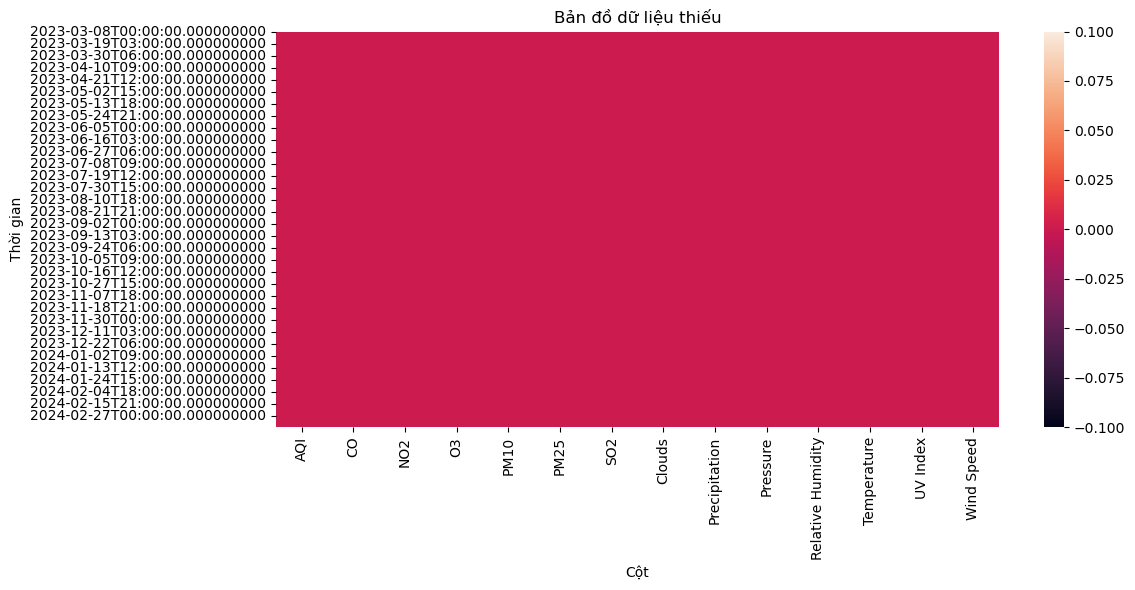

In [8]:
# Ve bieu do thieu du lieu 

plt.figure(figsize=(12, 6))
sns.heatmap(df.isna(), cbar=True)
plt.title("Bản đồ dữ liệu thiếu")
plt.xlabel("Cột")
plt.ylabel("Thời gian")
plt.tight_layout()
plt.show()

# IV. Tạo feature thời gian

In [9]:
df["hour"] = df.index.hour
df["dayofweek"] = df.index.dayofweek
df["month"] = df.index.month
df["day"] = df.index.day

# Ky thuat tao dac trung Future Engineering
df["is_weekend"] = df["dayofweek"].isin([5, 6]).astype(int) # 5 Saturday, 6 Sunday


In [10]:
# Vi gio trong ngay va thang co tinh chu ky nen co the ma hoa
df['hour_sin'] = np.sin(2 * np.pi * df['hour'] / 24)

df['hour_cos'] = np.cos(2 * np.pi * df['hour'] / 24)

df["month_sin"] = np.sin(2 * np.pi * df["month"] / 12)

df["month_cos"] = np.cos(2 * np.pi * df["month"] / 12)


# V. Phân tích theo giờ

## 1. Trung bình PM2.5 theo giờ

In [11]:
hourly_summary = df.groupby("hour")["PM25"].agg(
    mean = "mean", # trung binh
    median = "median", # trung vi 
    std = "std", # do lech chuan
    q25 = lambda x : x.quantile(0.25), # Phan vi 25%
    q75 = lambda x : x.quantile(0.75) # Phan vi 75%

)



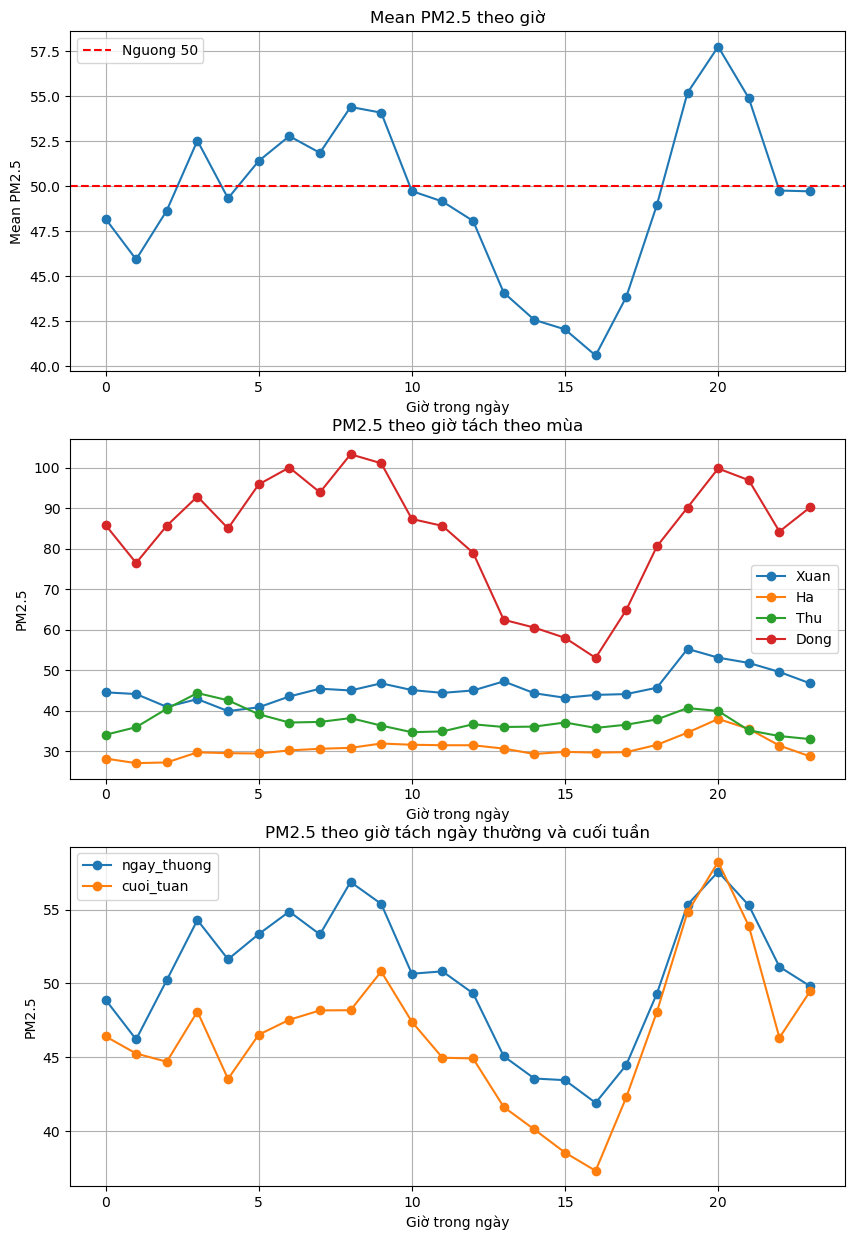

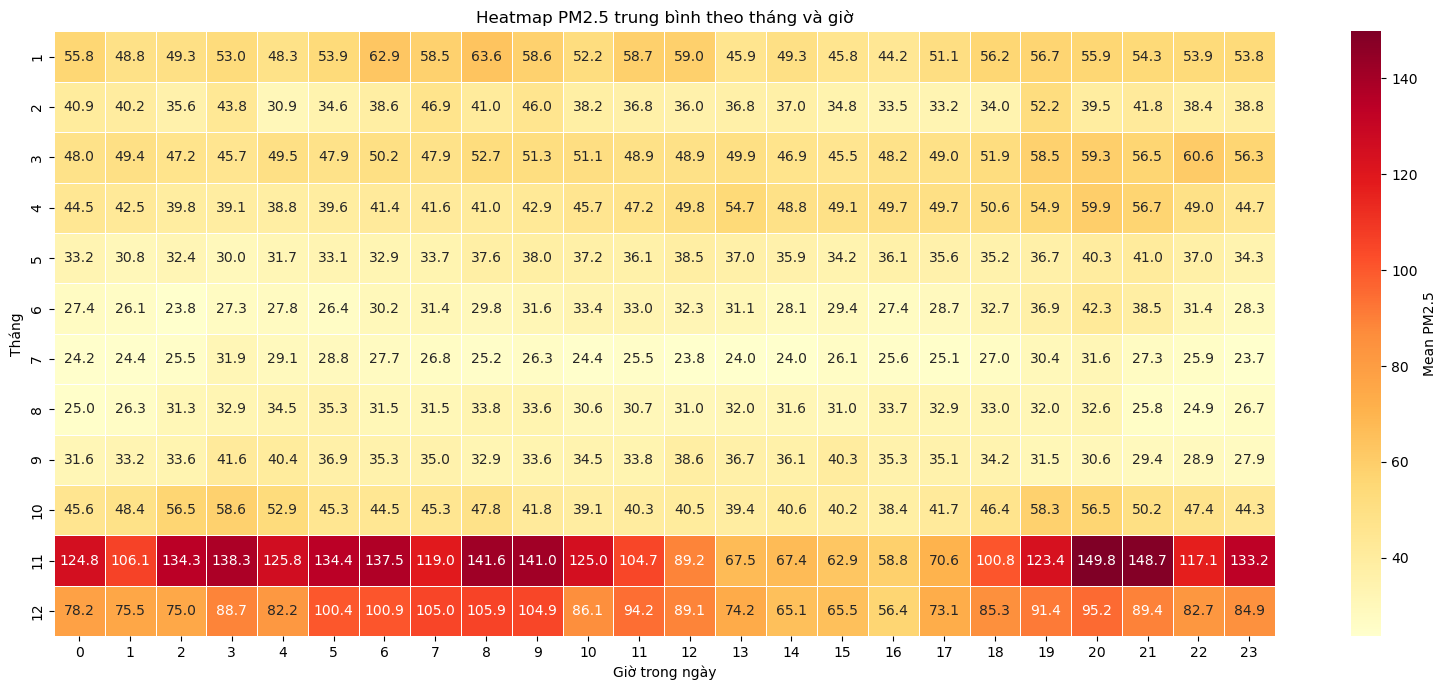

In [12]:
# Line chart: mean PM2.5 theo giờ
# Line chart: PM2.5 theo giờ nhưng tách theo mùa
# Line chart: PM2.5 theo giờ nhưng tách ngày thường và cuối tuần
# Heatmap: hàng là gio, cột là thang 

# Tao cac bieu do con 
fig, axs = plt.subplots(3, 1, figsize=(10,15))

# 1.Bieu do line chart: mean PM2.5 theo giờ
axs[0].plot(hourly_summary.index, hourly_summary["mean"], marker='o') # marker='o' de ve cac diem tren duong line
axs[0].set_title("Mean PM2.5 theo giờ")
axs[0].set_xlabel("Giờ trong ngày")
axs[0].set_ylabel("Mean PM2.5")
axs[0].axhline(y=50, color='red', linestyle='--', label = 'Nguong 50')
axs[0].grid(True)
axs[0].legend()

# 2.Bieu do line chart: PM2.5 theo giờ nhưng tách theo mùa

# Dinh nghia cac thang theo mua
seasons = {
    'Xuan': [2,3,4],
    'Ha': [5,6,7,],
    'Thu': [8,9,10],
    'Dong': [11,12,1]
}
seasonal_pm25 = {}
for season, months in seasons.items():
    seasonal_pm25[season] = df[df.index.month.isin(months)].groupby('hour')['PM25'].mean()

for season, data in seasonal_pm25.items():
    axs[1].plot(data.index, data.values, marker='o', label=season)

axs[1].set_title("PM2.5 theo giờ tách theo mùa")
axs[1].set_xlabel("Giờ trong ngày")
axs[1].set_ylabel("PM2.5")
axs[1].grid(True)
axs[1].legend()

# 3.Bieu do line chart: PM2.5 theo giờ nhưng tách ngày thường và cuối tuần
data_type = {'ngay_thuong', 'cuoi_tuan'}

for type in data_type:
    if type == 'ngay_thuong':
        data = df[df['is_weekend'] == 0].groupby('hour')['PM25'].mean()
    else:
        data = df[df['is_weekend'] == 1].groupby('hour')['PM25'].mean()
    
    axs[2].plot(data.index, data.values, marker='o', label=type)

axs[2].set_title("PM2.5 theo giờ tách ngày thường và cuối tuần")
axs[2].set_xlabel("Giờ trong ngày")
axs[2].set_ylabel("PM2.5")
axs[2].grid(True)
axs[2].legend()    


# 4. Heatmap hang la thang cot la gio trong ngay

# Tạo bảng:
# index = tháng
# columns = giờ trong ngày
# values = PM2.5 trung bình
heatmap_data = df.pivot_table(
    values= "PM25",
    index = df.index.month,
    columns = df.index.hour,
    aggfunc= "mean"
)

plt.figure(figsize=(16, 7))

sns.heatmap(
    heatmap_data, # data input
    cmap="YlOrRd", # color map
    annot=True, # Anotation chu thich
    fmt=".1f", # Format dinh dang : hien thi so thap phan
    linewidths=.5, # do rong duong
    cbar_kws={"label": "Mean PM2.5"} # color bar keyword
)

plt.title("Heatmap PM2.5 trung bình theo tháng và giờ")
plt.xlabel("Giờ trong ngày")
plt.ylabel("Tháng")
plt.tight_layout()
plt.show()









# VI. Phân tích theo mùa

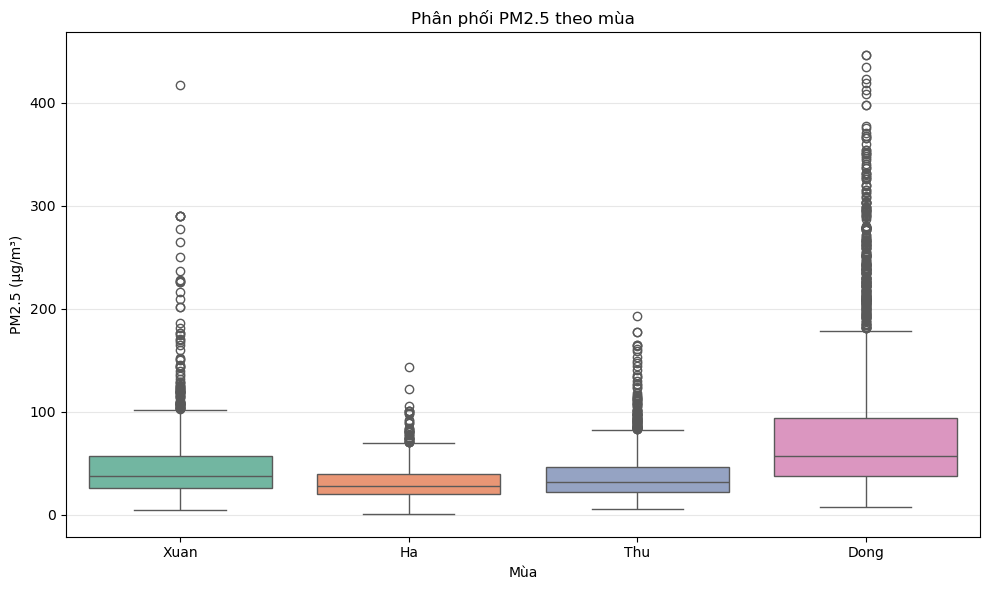

In [13]:
# Boxplot PM2.5 theo mua 
seasons = { 
    'Xuan': [2,3,4],
    'Ha': [5,6,7,],
    'Thu': [8,9,10],
    'Dong': [11,12,1]
}

# anh xa thang sang mau
def get_season(month):
    for season, months in seasons.items():
        if month in months:
            return season

df['Season'] = df['month'].apply(get_season)        
        

plt.figure(figsize=(10, 6))

sns.boxplot(
    data = df,
    x="Season", # chia du lieu 4 mua tren truc x
    y="PM25", 
    hue = "Season", # Dung mau de xac dinh mau sac tung nhom
    order = list(seasons.keys()),
    palette="Set2" # bang mau
)

plt.title("Phân phối PM2.5 theo mùa")
plt.xlabel("Mùa")
plt.ylabel("PM2.5 (μg/m³)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


# Đường giữa hộp: median PM2.5
# Cạnh dưới hộp: Q1, 25% dữ liệu
# Cạnh trên hộp: Q3, 75% dữ liệu
# Chiều cao hộp: mức độ phân tán của 50% dữ liệu trung tâm
# Các chấm riêng lẻ: outlier
# Râu hộp: phạm vi dữ liệu thông thường

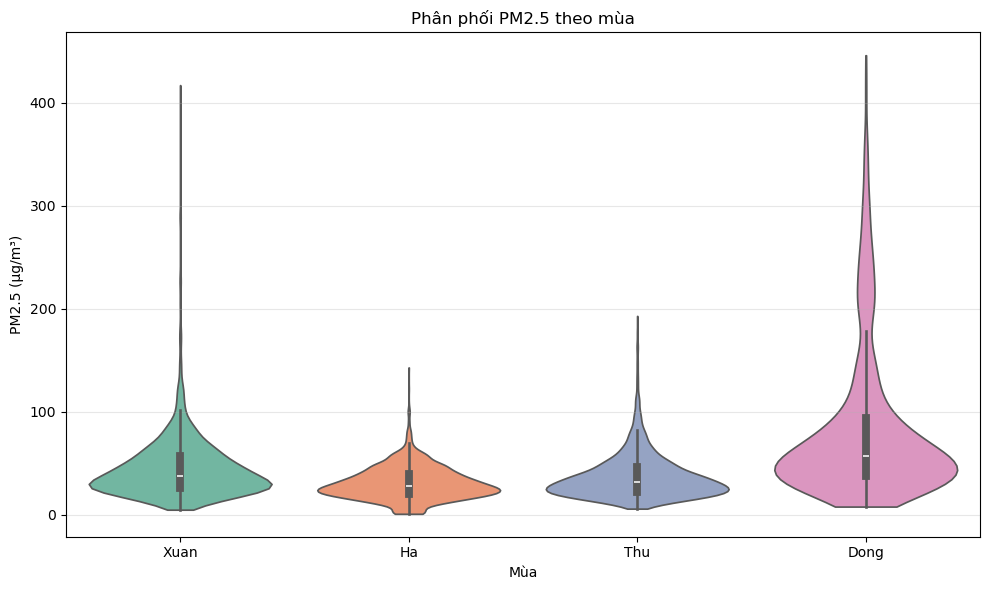

In [14]:
# Violin plot PM2.5 theo mùa

# Thứ tự hiển thị các mùa
season_order = ["Xuan", "Ha", "Thu", "Dong"]

plt.figure(figsize=(10, 6))

sns.violinplot(
    data=df, # dataframe chua du lieu can ve
    x="Season",
    y="PM25",
    order=season_order, # thu tu xuat hien cac mua
    hue="Season",
    palette="Set2",
    inner="box", # hien thi boxplot ben trong violin plot
    cut=0, # gioi han phan violin plot tai gia tri min va max cua data
    legend=False
)

plt.title("Phân phối PM2.5 theo mùa")
plt.xlabel("Mùa")
plt.ylabel("PM2.5 (μg/m³)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

C:\Users\minhl\AppData\Local\Temp\ipykernel_29740\1403774690.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\minhl\AppData\Local\Temp\ipykernel_29740\1403774690.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\minhl\AppData\Local\Temp\ipykernel_29740\1403774690.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\minhl\AppData\Local\Temp\ipykernel_29740\1403774690.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `h

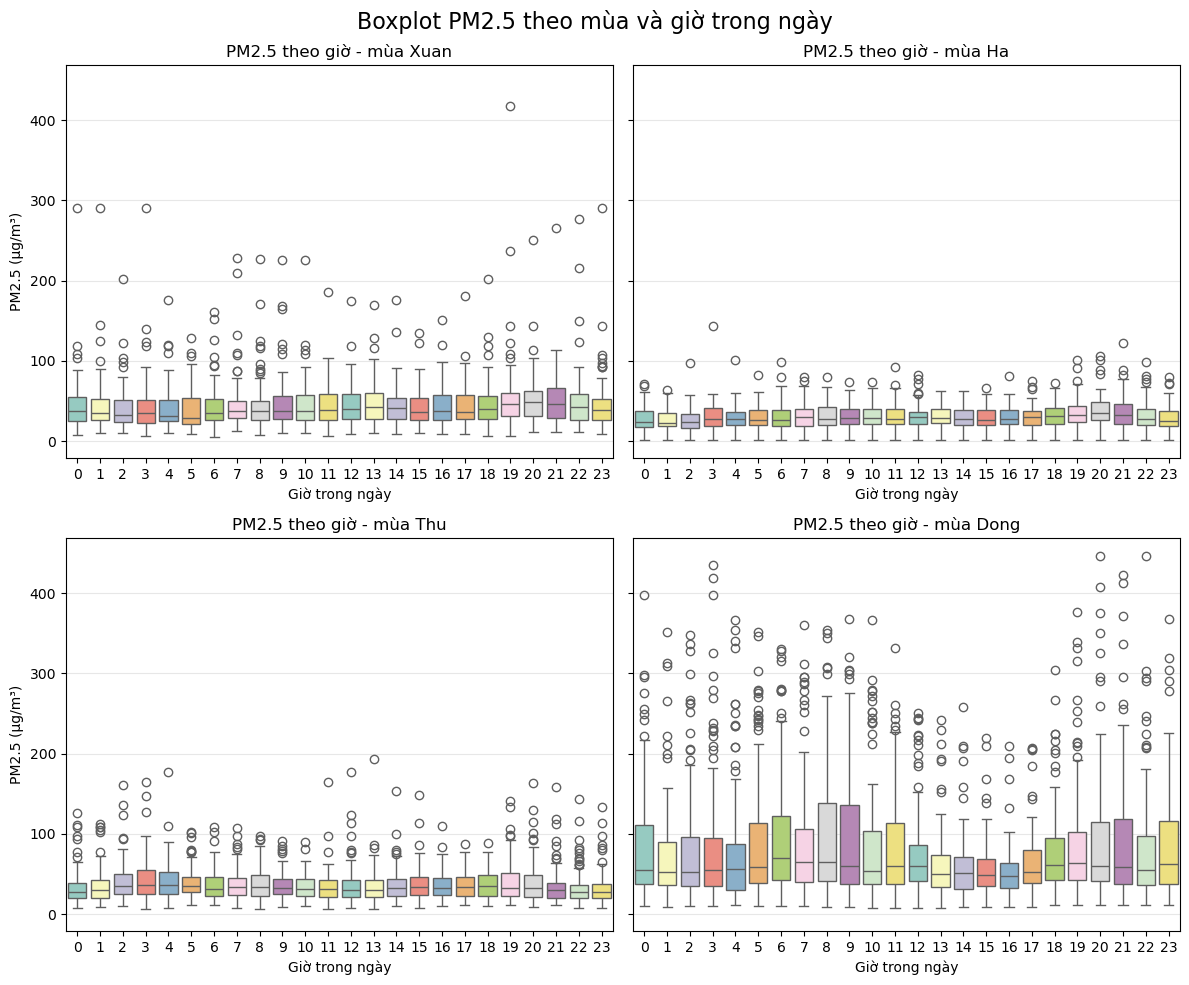

In [15]:
season_order = ["Xuan", "Ha", "Thu", "Dong"]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(12,10),
    sharey=True
)

axes = axes.flatten() # chuyen mang 2D thanh 1D de de duyet qua tung trục

for ax, season in zip(axes, season_order):

    season_data = df[df["Season"] == season]

    sns.boxplot(
        data = season_data,
        x='hour',
        y='PM25',
        order = list(range(24)),
        ax=ax, # chi dinh chinh xac o bieu do can ve
        palette="Set3",
        showfliers=True # hien cac diem outlier
    )
    ax.set_title(f"PM2.5 theo giờ - mùa {season}")
    ax.set_xlabel("Giờ trong ngày")
    ax.set_ylabel("PM2.5 (μg/m³)")
    ax.grid(axis="y", alpha=0.3)

plt.suptitle(
    "Boxplot PM2.5 theo mùa và giờ trong ngày",
    fontsize=16
)


plt.tight_layout()
plt.show()




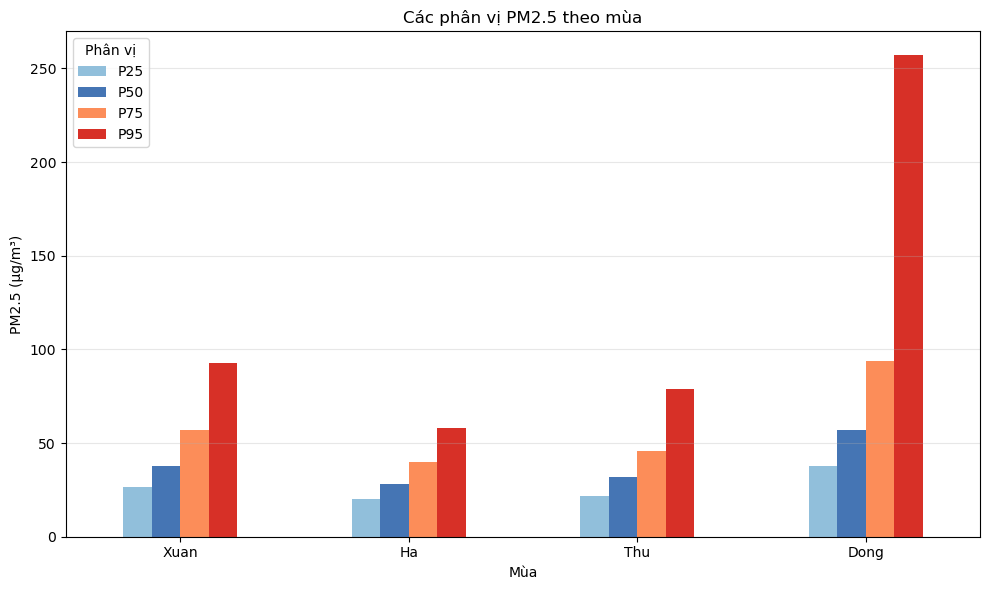

In [16]:
# Phân vị P25, P50, P75 và P95 theo mùa

# P25: 25% số giờ có PM2.5 nhỏ hơn hoặc bằng giá trị này.
# P50: median; 50% số giờ có PM2.5 nhỏ hơn hoặc bằng giá trị này.
# P75: 75% số giờ có PM2.5 nhỏ hơn hoặc bằng giá trị này.
# P95: 95% số giờ có PM2.5 nhỏ hơn hoặc bằng giá trị này; 5% số giờ còn lại cao hơn P95.

season_order = ["Xuan", "Ha", "Thu", "Dong"]

quantile_table = (
    df.groupby('Season')['PM25']
    .quantile([0.25, 0.5, 0.75, 0.95]) # tinh cac phan vi
    .unstack() # chuyen index phan vi tu hang  thanh cot
    .reindex(season_order) # sap xep lai theo thu tu cac mua
)

quantile_table.columns = ["P25", "P50", "P75", "P95"]
quantile_table = quantile_table.round(2)

quantile_table

quantile_table.plot(
    kind="bar",
    figsize=(10, 6),
    color=["#91bfdb", "#4575b4", "#fc8d59", "#d73027"]
)

plt.title("Các phân vị PM2.5 theo mùa")
plt.xlabel("Mùa")
plt.ylabel("PM2.5 (μg/m³)")
plt.xticks(rotation=0)
plt.legend(title="Phân vị")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [17]:
# Tỷ lệ giờ vượt các ngưỡng PM2.5

thresholds = [12, 35.5, 55.5, 150.5, 250.5]

season_order = ["Xuan", "Ha", "Thu", "Dong"]

season_threshold_results = {}

for season in season_order:
    for threshold in thresholds:

        season_data = df[df['Season'] == season]

        result = (season_data['PM25'] > threshold).mean() * 100

        season_threshold_results[(season, threshold)] = result


# Chuyển dictionary thành DataFrame
result_df = pd.DataFrame(
    [
        {
            'Season': season,
            'Threshold': threshold,
            'Exceedance_Rate': rate
        }
        for (season, threshold), rate in season_threshold_results.items()
    ]
)


# Xoay bảng
pivot_table = result_df.pivot(
    index='Season',
    columns='Threshold',
    values='Exceedance_Rate'
)

# Sắp xếp thứ tự mùa
pivot_table = pivot_table.reindex(season_order)

# Đổi tên cột
pivot_table.columns = [f"Trên {threshold}" for threshold in pivot_table.columns]

pivot_table

,Trên 12.0,Trên 35.5,Trên 55.5,Trên 150.5,Trên 250.5
Season,,,,,
Xuan,96.668209,55.020824,26.376677,1.341971,0.323924
Ha,91.168478,32.880435,6.974638,0.000000,0.000000
Thu,97.101449,41.621377,14.764493,0.407609,0.000000
Dong,98.596014,77.083333,50.996377,14.356884,5.661232


# VII. Phân tích theo ngày trong tuần

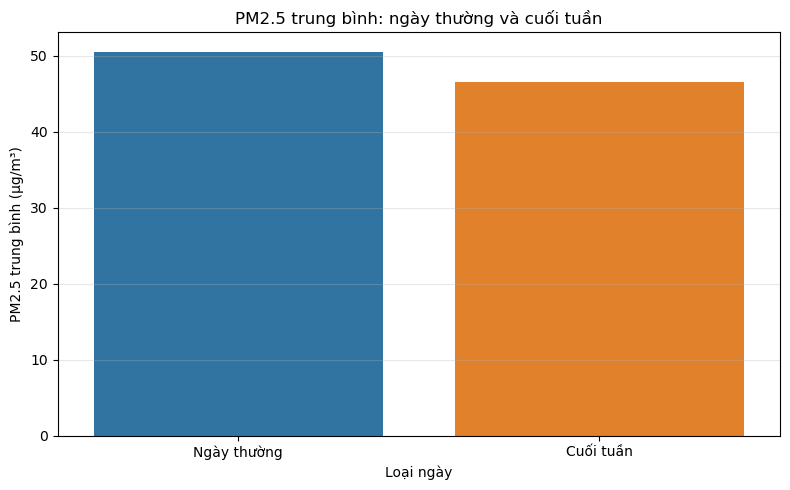

In [18]:
# Trung bình PM2.5 ngày thường và cuối tuần

weekday_weekend_mean = (
    df.groupby('is_weekend')["PM25"].mean().reindex([0, 1])
  
)

weekday_weekend_mean.index = ["Ngày thường", "Cuối tuần"]

plt.figure(figsize=(8, 5))

sns.barplot(
    data=weekday_weekend_mean.reset_index(),
    x=weekday_weekend_mean.index,
    y=weekday_weekend_mean.values,
    hue = weekday_weekend_mean.index,
    palette=["#1f77b4", "#ff7f0e"]
)

plt.title("PM2.5 trung bình: ngày thường và cuối tuần")
plt.xlabel("Loại ngày")
plt.ylabel("PM2.5 trung bình (μg/m³)")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

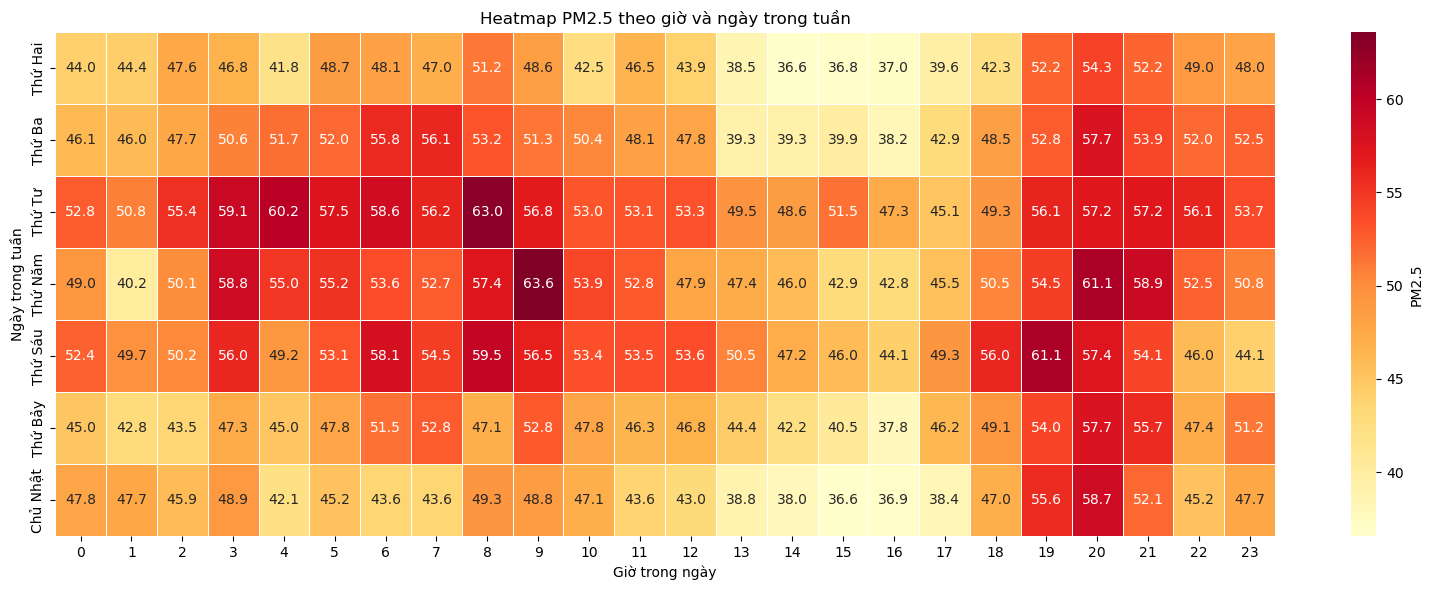

In [19]:
# Heatmap giờ × ngày trong tuần

day_names = {
    0: "Thứ Hai",
    1: "Thứ Ba",
    2: "Thứ Tư",
    3: "Thứ Năm",
    4: "Thứ Sáu",
    5: "Thứ Bảy",
    6: "Chủ Nhật"
}


df["day_name"] = df["dayofweek"].map(day_names)

day_order = [
    "Thứ Hai",
    "Thứ Ba",
    "Thứ Tư",
    "Thứ Năm",
    "Thứ Sáu",
    "Thứ Bảy",
    "Chủ Nhật"
]

heatmap_data = df.pivot_table(
    values = "PM25",
    index= "day_name",
    columns= "hour",
    aggfunc= "mean"
).reindex(
    index = day_order,
    columns=range(24)
)

heatmap_data

plt.figure(figsize=(16,6))

sns.heatmap(
    heatmap_data,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=.5,
    cbar_kws={"label": "PM2.5"}
)

plt.title("Heatmap PM2.5 theo giờ và ngày trong tuần")
plt.xlabel("Giờ trong ngày")
plt.ylabel("Ngày trong tuần")
plt.tight_layout()
plt.show()

<Axes: xlabel='hour', ylabel='day_name'>

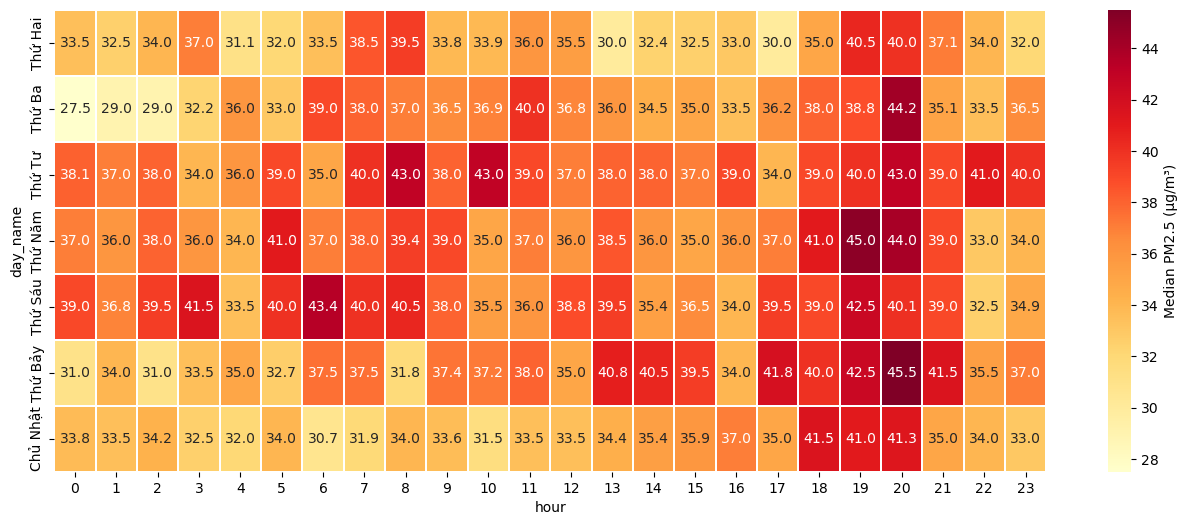

In [20]:
heatmap_median = df.pivot_table(
    values="PM25",
    index="day_name",
    columns="hour",
    aggfunc="median"
).reindex(
    index=day_order,
    columns=range(24)
)

plt.figure(figsize=(16, 6))

sns.heatmap(
    heatmap_median,
    cmap="YlOrRd",
    annot=True,
    fmt=".1f",
    linewidths=0.3,
    cbar_kws={"label": "Median PM2.5 (μg/m³)"}
)


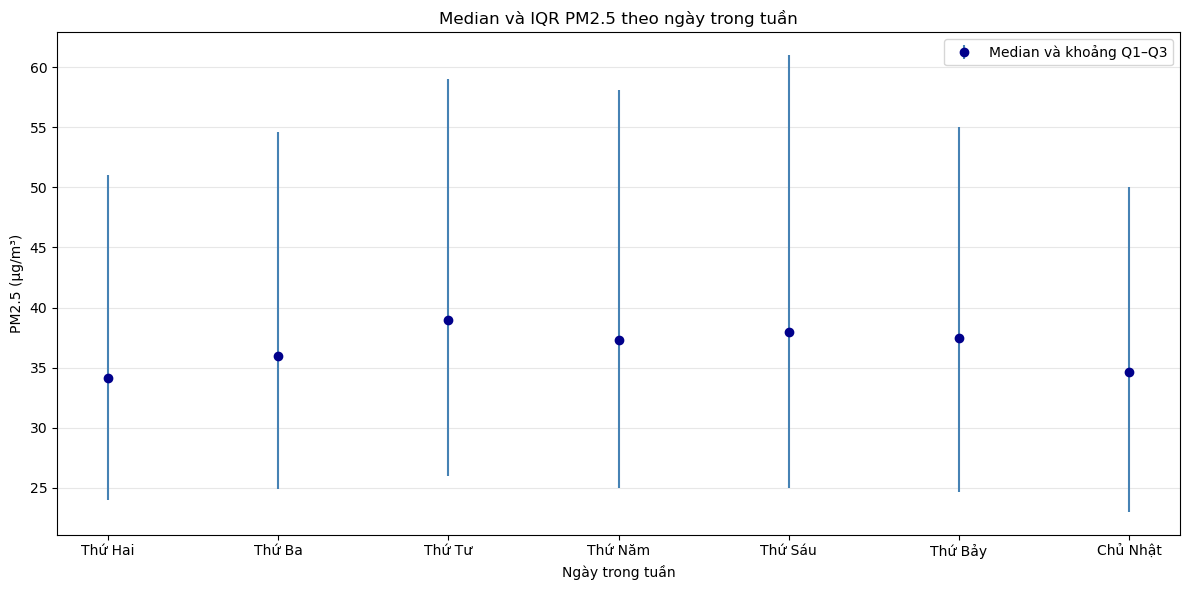

In [21]:
# Median và IQR theo từng ngày

daily_summary = (
    df.groupby("day_name")["PM25"]
      .agg(
          count="count",
          mean="mean",
          median="median",
          q1=lambda x: x.quantile(0.25),
          q3=lambda x: x.quantile(0.75)
      )
      .reindex(day_order)
)

daily_summary["IQR"] = (
    daily_summary["q3"] - daily_summary["q1"]
)

daily_summary.round(2)

plt.figure(figsize=(12, 6))

x = np.arange(len(daily_summary))


# Error bar : thanh sai so 
plt.errorbar(
    day_order,  # vi tri tung ngay tren truc x
    daily_summary["median"],
    yerr=[
        daily_summary["median"] - daily_summary["q1"],
        daily_summary["q3"] - daily_summary["median"]
    ], # tao thanh keo dai tu Q1 den Q3
    fmt="o", # diem median bieu dien bang hinh tron
    color="darkblue", # mau diem median
    ecolor="steelblue", # mau thanh Q1 - Q3
    label="Median và khoảng Q1–Q3"
)

plt.xlabel("Ngày trong tuần")
plt.ylabel("PM2.5 (μg/m³)")
plt.title("Median và IQR PM2.5 theo ngày trong tuần")
plt.grid(axis="y", alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# VIII. Phân tích tác động trễ

In [22]:
lags = [1, 3, 6, 12, 24, 48, 72, 168]

for lag in lags:
    df[f"PM25_lag_{lag}"] = df["PM25"].shift(lag)


pm25_lag_corr = {}

for lag in lags:
    column = f"PM25_lag_{lag}"

    pm25_lag_corr[lag] = df["PM25"].corr(
        df[column]
    )

pm25_lag_corr = pd.Series(pm25_lag_corr)
pm25_lag_corr   


1      0.880781
3      0.776540
6      0.676567
12     0.603471
24     0.703857
48     0.583543
72     0.498426
168    0.312512
dtype: float64

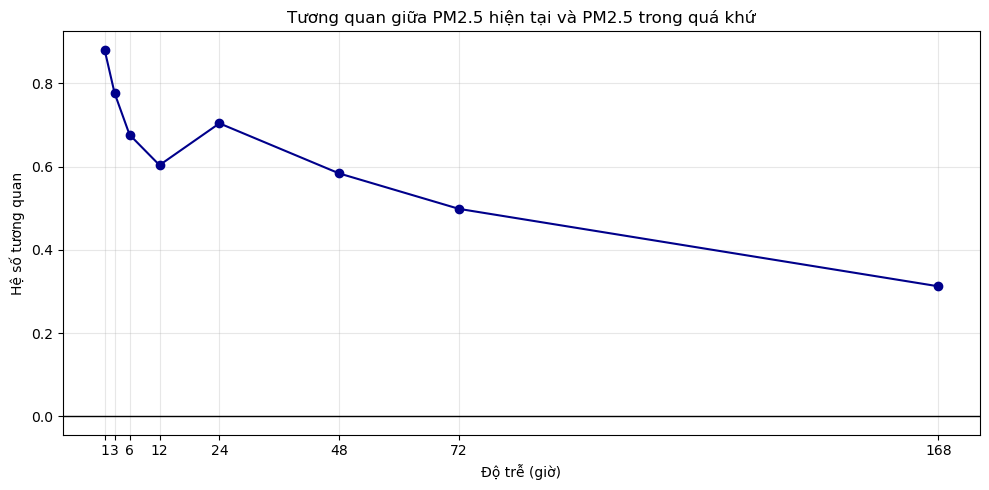

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(
    pm25_lag_corr.index,
    pm25_lag_corr.values,
    marker="o",
    color="darkblue"
)

plt.axhline(0, color="black", linewidth=1)
plt.title("Tương quan giữa PM2.5 hiện tại và PM2.5 trong quá khứ")
plt.xlabel("Độ trễ (giờ)")
plt.ylabel("Hệ số tương quan")
plt.xticks(lags)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# IX. Phân tích mối quan hệ phi tuyến

In [24]:
# Kiem tra cot du lieu
weather_columns = [
    "Temperature",
    "Relative Humidity",
    "Precipitation",
    "Pressure",
    "Wind Speed"
]

weather_columns = [
    column for column in weather_columns
    if column in df.columns
]

print(weather_columns)

['Temperature', 'Relative Humidity', 'Precipitation', 'Pressure', 'Wind Speed']


In [25]:
# Loai du lieu thieu

# Tao DF chi chua cot PM2.5 va cac cot thoi tiet
df_nonlinear = df[['PM25'] + weather_columns].copy()

df_nonlinear = df_nonlinear.dropna()
df_nonlinear.shape

df_nonlinear.head(25)

,PM25,Temperature,Relative Humidity,Precipitation,Pressure,Wind Speed
Local Time,,,,,,
2023-03-08 00:00:00,47.0,21.2,86.0,0.00,1016.0,2.00
2023-03-08 01:00:00,45.0,21.1,89.0,0.00,1016.0,2.00
2023-03-08 02:00:00,42.0,20.9,90.0,0.00,1016.0,1.66
2023-03-08 03:00:00,45.0,20.7,91.0,0.00,1016.0,1.33
2023-03-08 04:00:00,42.0,20.5,92.0,0.00,1015.0,1.00
2023-03-08 05:00:00,39.0,20.5,91.0,0.00,1016.0,1.66
2023-03-08 06:00:00,35.0,20.5,90.0,0.00,1017.0,2.33
2023-03-08 07:00:00,40.0,20.5,89.0,0.00,1018.0,3.00
2023-03-08 08:00:00,43.0,20.8,88.0,0.00,1018.0,3.00


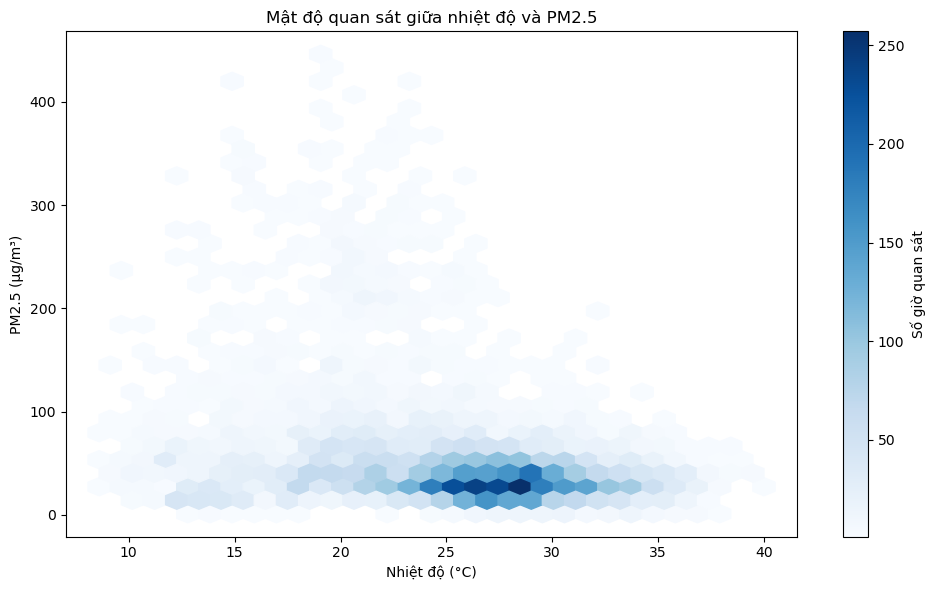

In [26]:
# Nhiet do va PM2.5

plt.figure(figsize=(10, 6))

plt.hexbin(
    df_nonlinear['Temperature'],
    df_nonlinear['PM25'],
    gridsize=30,
    cmap='Blues',
    mincnt=1
)

plt.colorbar(label="Số giờ quan sát")
plt.xlabel("Nhiệt độ (°C)")
plt.ylabel("PM2.5 (μg/m³)")
plt.title("Mật độ quan sát giữa nhiệt độ và PM2.5")
plt.tight_layout()
plt.show()

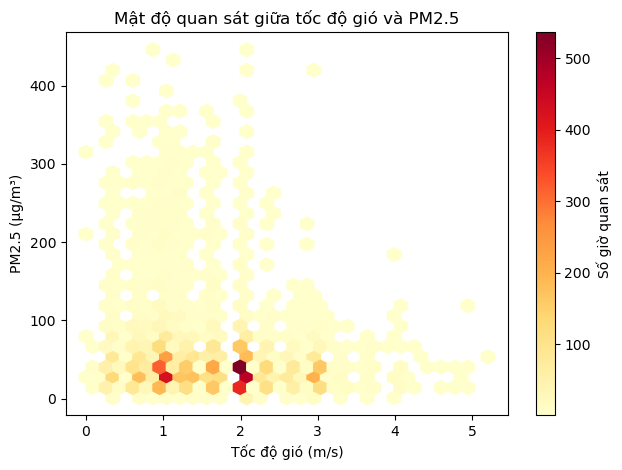

In [27]:
# Toc do gio va PM2.5

plt.hexbin(
    df_nonlinear["Wind Speed"],
    df_nonlinear["PM25"],
    gridsize=30,
    cmap="YlOrRd",
    mincnt=1
)

plt.colorbar(label="Số giờ quan sát")
plt.xlabel("Tốc độ gió (m/s)")
plt.ylabel("PM2.5 (μg/m³)")
plt.title("Mật độ quan sát giữa tốc độ gió và PM2.5")
plt.tight_layout()
plt.show()


In [28]:
# Chia bien thoi tiet thanh cac khoang bang quantile

for col in weather_columns:
    df[f"{col}_bin"] = pd.qcut(
        df_nonlinear[col],
        q=5, # chia thanh 5 khoang bang nhau
        duplicates='drop'  # neu co gia tri trung nhau, se loai bo cac khoang trung lap
    )

df    

,AQI,CO,NO2,O3,PM10,PM25,SO2,Clouds,Precipitation,Pressure,Relative Humidity,Temperature,UV Index,Wind Speed,hour,dayofweek,month,day,is_weekend,hour_sin,hour_cos,month_sin,month_cos,Season,day_name,PM25_lag_1,PM25_lag_3,PM25_lag_6,PM25_lag_12,PM25_lag_24,PM25_lag_48,PM25_lag_72,PM25_lag_168,Temperature_bin,Relative Humidity_bin,Precipitation_bin,Pressure_bin,Wind Speed_bin
Local Time,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
2023-03-08 00:00:00,131.0,170.6,29.3,53.3,58.8,47.00,67.3,91.0,0.0,1016.0,86.0,21.2,0.0,2.00,0,2,3,8,0,0.000000,1.000000,1.0,6.123234e-17,Xuan,Thứ Tư,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"(20.5, 24.7]","(77.0, 86.0]","(-0.001, 22.75]","(1012.0, 1017.0]","(1.33, 2.0]"
2023-03-08 01:00:00,126.0,158.7,25.0,54.0,56.3,45.00,65.0,100.0,0.0,1016.0,89.0,21.1,0.0,2.00,1,2,3,8,0,0.258819,0.965926,1.0,6.123234e-17,Xuan,Thứ Tư,47.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"(20.5, 24.7]","(86.0, 92.0]","(-0.001, 22.75]","(1012.0, 1017.0]","(1.33, 2.0]"
2023-03-08 02:00:00,118.0,150.2,21.7,55.0,52.5,42.00,65.7,100.0,0.0,1016.0,90.0,20.9,0.0,1.66,2,2,3,8,0,0.500000,0.866025,1.0,6.123234e-17,Xuan,Thứ Tư,45.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"(20.5, 24.7]","(86.0, 92.0]","(-0.001, 22.75]","(1012.0, 1017.0]","(1.33, 2.0]"
2023-03-08 03:00:00,126.0,141.6,18.3,56.0,56.3,45.00,66.3,100.0,0.0,1016.0,91.0,20.7,0.0,1.33,3,2,3,8,0,0.707107,0.707107,1.0,6.123234e-17,Xuan,Thứ Tư,42.00,47.00,NaN,NaN,NaN,NaN,NaN,NaN,"(20.5, 24.7]","(86.0, 92.0]","(-0.001, 22.75]","(1012.0, 1017.0]","(1.0, 1.33]"
2023-03-08 04:00:00,118.0,133.1,15.0,57.0,52.5,42.00,67.0,100.0,0.0,1015.0,92.0,20.5,0.0,1.00,4,2,3,8,0,0.866025,0.500000,1.0,6.123234e-17,Xuan,Thứ Tư,45.00,45.00,NaN,NaN,NaN,NaN,NaN,NaN,"(8.599, 20.5]","(86.0, 92.0]","(-0.001, 22.75]","(1012.0, 1017.0]","(-0.001, 1.0]"
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2024-03-07 20:00:00,193.0,6738.4,36.7,21.4,139.3,87.86,12.0,100.0,0.0,1014.0,71.0,21.5,0.0,1.00,20,3,3,7,0,-0.866025,0.500000,1.0,6.123234e-17,Xuan,Thứ Năm,85.71,76.75,44.43,39.4,78.86,100.25,68.83,17.33,"(20.5, 24.7]","(64.0, 77.0]","(-0.001, 22.75]","(1012.0, 1017.0]","(-0.001, 1.0]"
2024-03-07 21:00:00,173.0,6693.2,29.3,19.5,140.6,73.00,6.0,100.0,0.0,1015.0,75.0,21.1,0.0,1.00,21,3,3,7,0,-0.707107,0.707107,1.0,6.123234e-17,Xuan,Thứ Năm,87.86,84.20,46.14,39.0,60.50,114.00,65.00,15.60,"(20.5, 24.7]","(64.0, 77.0]","(-0.001, 22.75]","(1012.0, 1017.0]","(-0.001, 1.0]"
2024-03-07 22:00:00,241.0,504.0,108.0,18.4,167.0,124.00,116.0,100.0,0.0,1016.0,80.0,20.6,0.0,1.00,22,3,3,7,0,-0.500000,0.866025,1.0,6.123234e-17,Xuan,Thứ Năm,73.00,85.71,57.38,25.4,55.80,150.20,216.00,11.33,"(20.5, 24.7]","(77.0, 86.0]","(-0.001, 22.75]","(1012.0, 1017.0]","(-0.001, 1.0]"


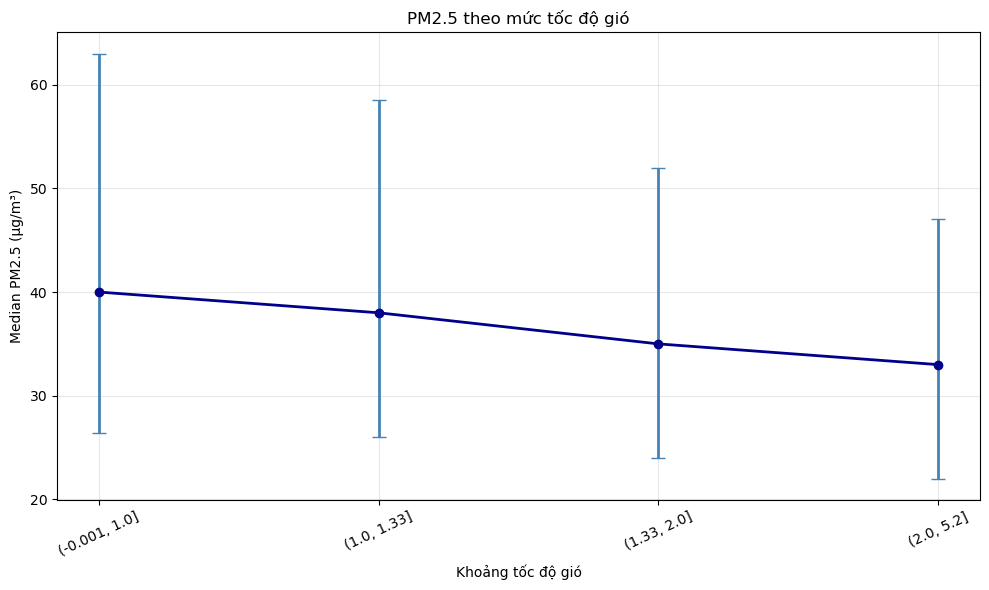

In [29]:
# Tính median PM2.5 trong từng khoảng

wind_effect = (
    df
    .groupby("Wind Speed_bin", observed=True)["PM25"]
    .agg(
        median="median",
        mean="mean",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        count="count"
    )
)

wind_effect

plt.figure(figsize=(10,6))

plt.errorbar(
    range(len(wind_effect)),
    wind_effect['median'],
    yerr= [
        wind_effect["median"] - wind_effect["q25"],
        wind_effect["q75"] - wind_effect["median"]
    ],
      marker="o",
    linewidth=2,
    capsize=5,
    color="darkblue",
    ecolor="steelblue"
)

plt.xticks(
    range(len(wind_effect)),
    [str(interval) for interval in wind_effect.index],
    rotation=25
)


plt.xlabel("Khoảng tốc độ gió")
plt.ylabel("Median PM2.5 (μg/m³)")
plt.title("PM2.5 theo mức tốc độ gió")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

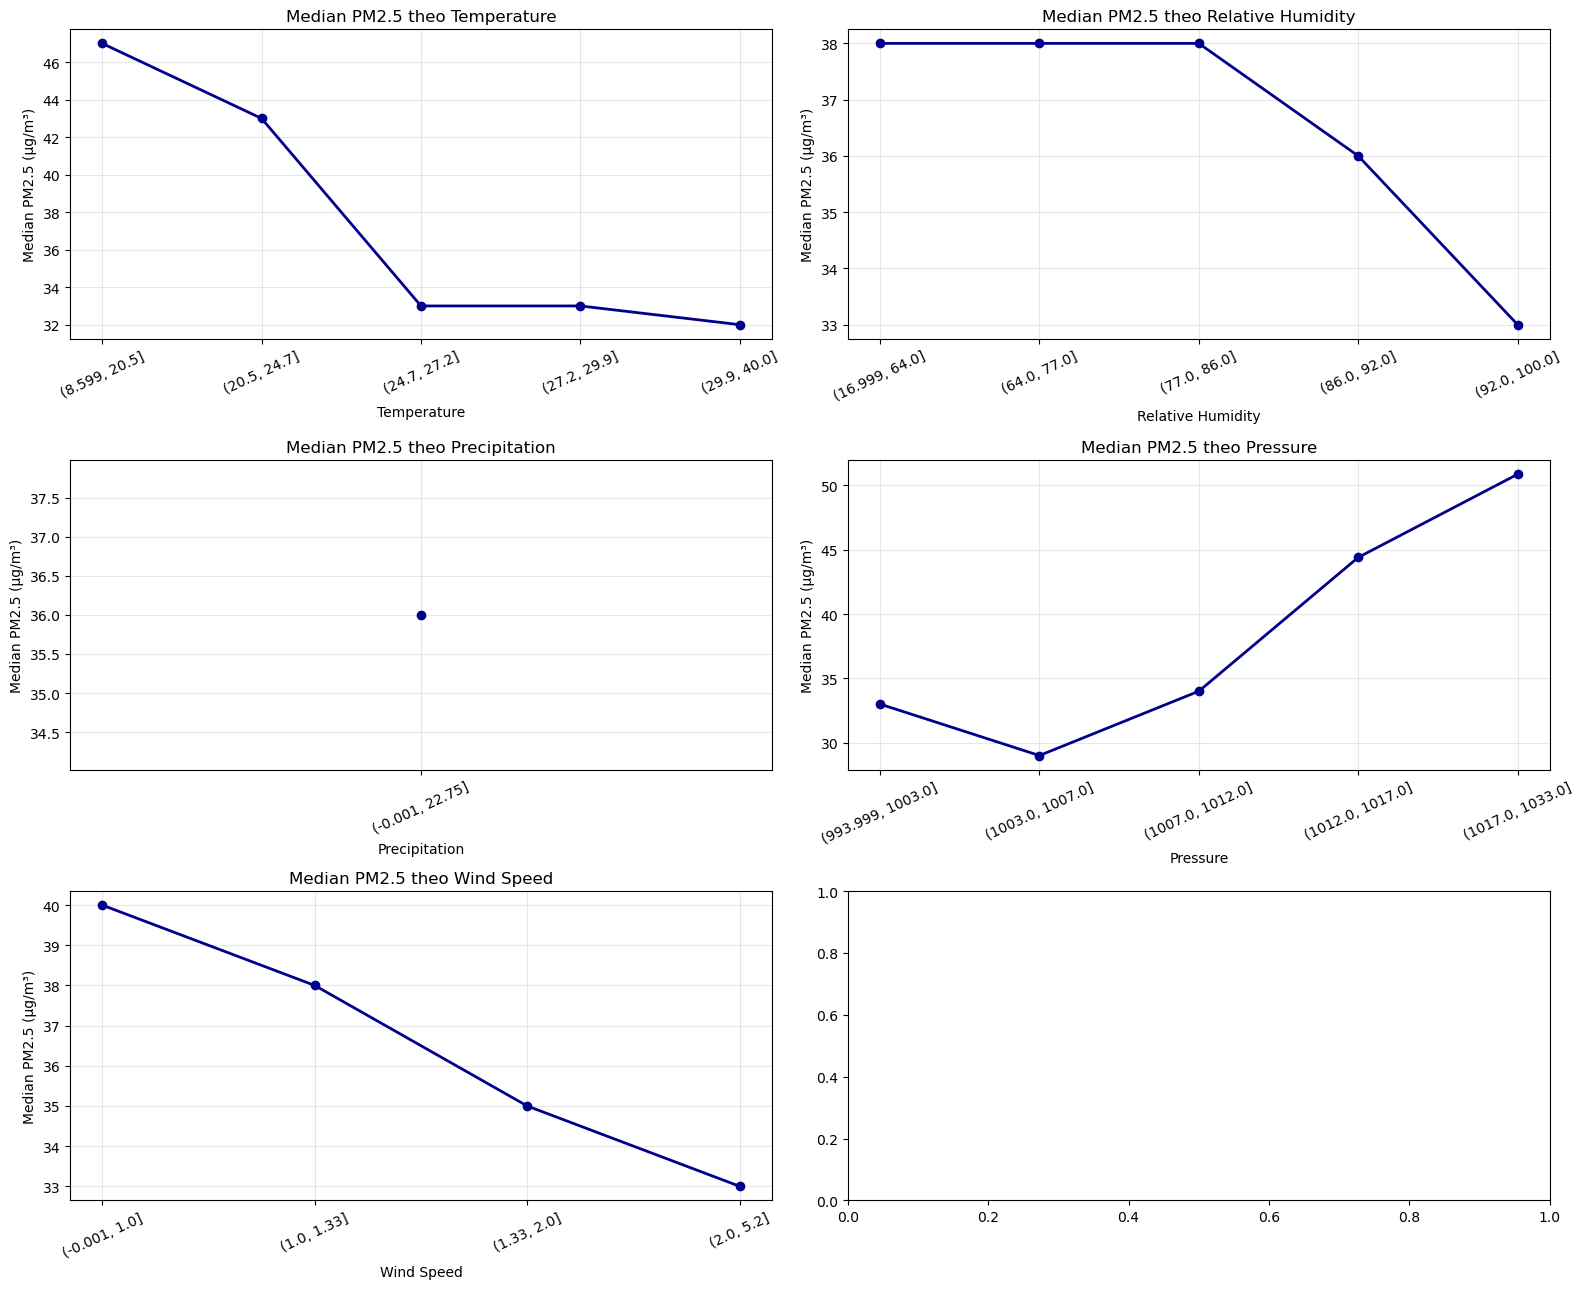

In [30]:
n_columns = 2
n_rows = 3

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(16, 13),
)

axes = axes.flatten()

for ax , column in zip(axes,weather_columns):

    column_bin = f"{column}_bin"

    summary = (
        df
        .groupby(column_bin, observed=True)["PM25"] 
        .median()
    )

    ax.plot(
        summary.index.astype(str),
        # range(len(summary)),
        summary.values,
        marker='o',
        linewidth =2, 
        color = "darkblue"
    )

    ax.set_xticks(
        range(len(summary)),
        [str(interval) for interval in summary.index],
        rotation=25         
        )

    ax.set_title(f"Median PM2.5 theo {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("Median PM2.5 (μg/m³)")
    ax.grid(alpha=0.3)

   
plt.tight_layout()
plt.show()
    

d:\App_Dowloaded\Anaconda\Lib\site-packages\statsmodels\nonparametric\smoothers_lowess.py:226: RuntimeWarning: invalid value encountered in divide
  res, _ = _lowess(y, x, x, np.ones_like(x),


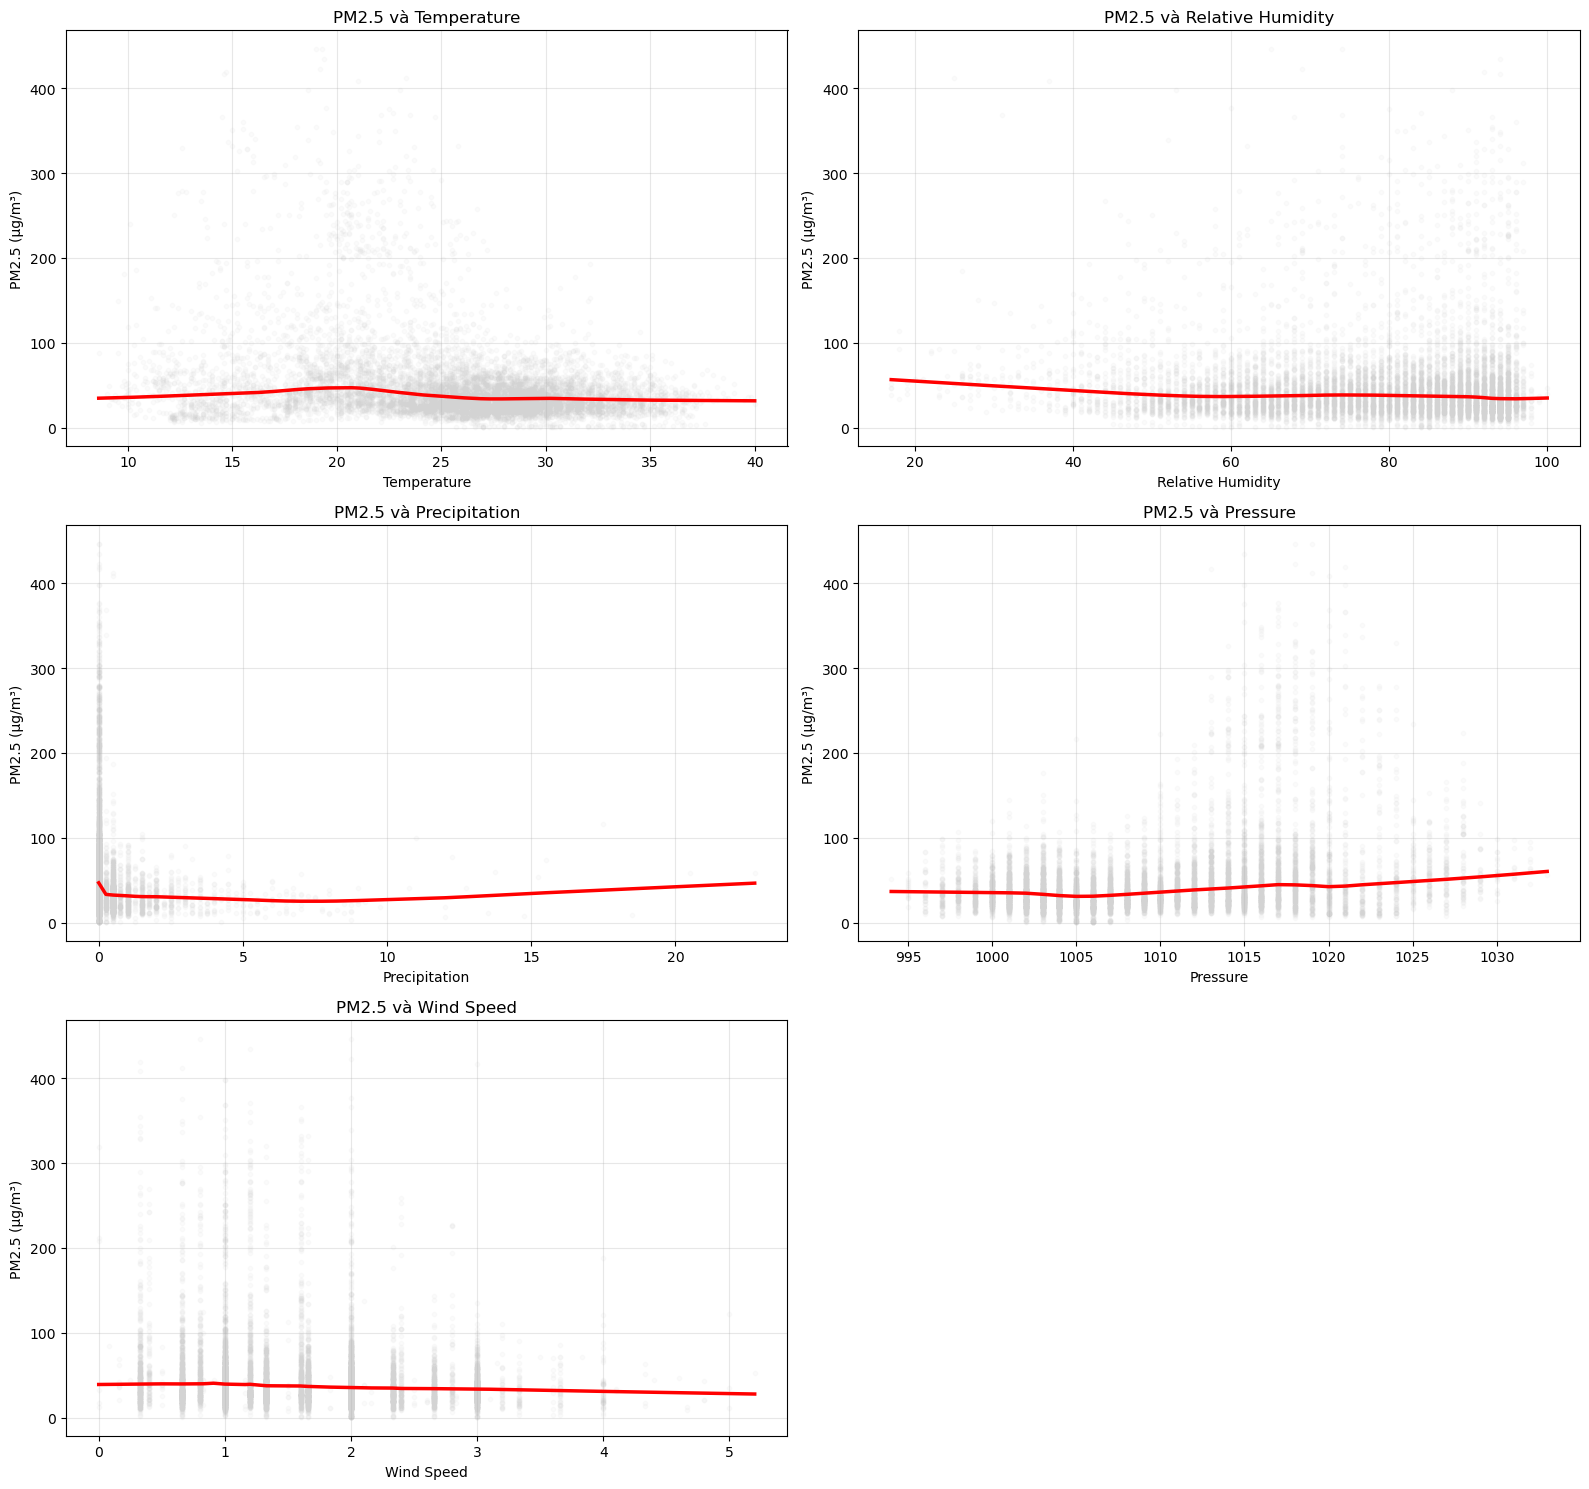

In [31]:
import statsmodels.api as sm
n_columns = 2
n_rows = (
    len(weather_columns) + n_columns - 1
) // n_columns

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(16, 5 * n_rows)
)

axes = axes.flatten()

for ax, column in zip(axes, weather_columns):
    data = df_nonlinear[[column, "PM25"]].dropna()

    lowess_result = sm.nonparametric.lowess( # tinh toan duong xu huong lowess
        endog=data["PM25"], # bien phu thuoc
        exog=data[column],  # bien doc lap 
        frac=0.3, # uoc luong xu huong se su dung khoang 30% du lieu de tinh toan
        return_sorted=True
    )

    lowess_result

    ax.scatter(
        data[column],
        data["PM25"],
        alpha=0.08,
        s=10,
        color="lightgray"
    )

    ax.plot(
        lowess_result[:, 0], # ':' lay tat ca cac hang, lay cot 0 (bien doc lap) va cot 1 (bien phu thuoc) 
        lowess_result[:, 1],
        color="red",
        linewidth=2.5
    )

    ax.set_title(f"PM2.5 và {column}")
    ax.set_xlabel(column)
    ax.set_ylabel("PM2.5 (μg/m³)")
    ax.grid(alpha=0.3)

for ax in axes[len(weather_columns):]:
    fig.delaxes(ax)

plt.tight_layout()
plt.show()

# X. Tương quan và kiểm định thống kê

Phần này đánh giá mức độ liên hệ giữa PM2.5 và các biến thời tiết, đồng thời kiểm tra xem sự khác biệt giữa các nhóm có ý nghĩa thống kê hay không.

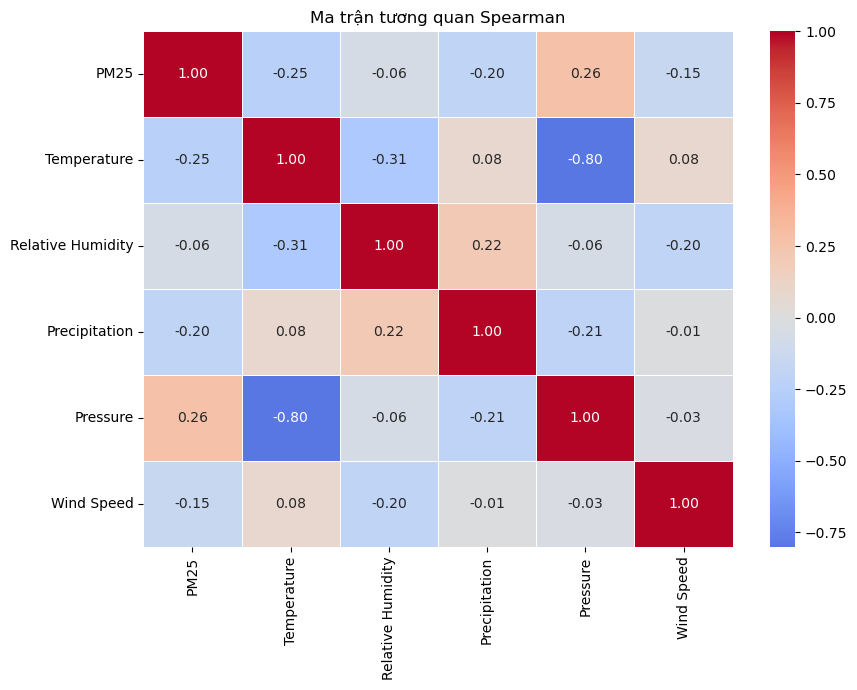

In [32]:
# Tương quan Spearman dua tren thu hang

columns = [
    "PM25",
    "Temperature",
    "Relative Humidity",
    "Precipitation",
    "Pressure",
    "Wind Speed"
]

columns = [column for column in columns if column in df.columns]

corr_spearman = df[columns].corr(method="spearman")

corr_spearman

plt.figure(figsize=(9, 7))

sns.heatmap(
    corr_spearman,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f",
    linewidths=0.5
)

plt.title("Ma trận tương quan Spearman")
plt.tight_layout()
plt.show()

# XI. Phân rã chuỗi thời gian PM2.5

Phần này tách PM2.5 thành trend dài hạn, seasonal lặp lại theo chu kỳ và residual là phần biến động còn lại.

Số ngày: 367
Thời gian bắt đầu: 2023-03-08 00:00:00
Thời gian kết thúc: 2024-03-08 00:00:00


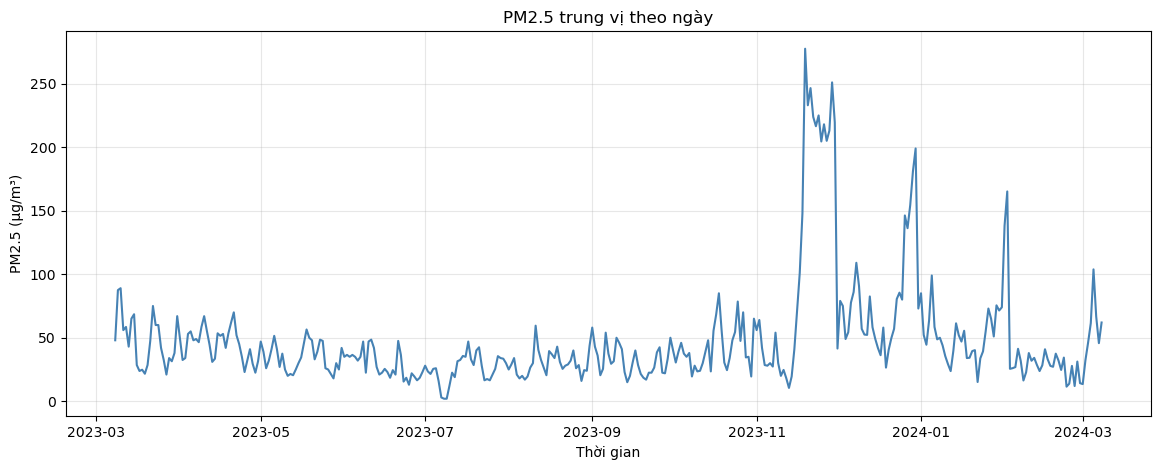

In [33]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Gom dữ liệu theo ngày bằng median để giảm ảnh hưởng của các đợt PM2.5 cực cao
daily_pm25 = df['PM25'].resample('D').median()

# Nội suy tối đa 7 ngày nếu có dữ liệu thiếu liên tục
daily_pm25 = daily_pm25.interpolate(method='time', limit=7)
# interpolate : dung de noi suy cac gia tri thieu


print('Số ngày:', len(daily_pm25))
print('Thời gian bắt đầu:', daily_pm25.index.min())
print('Thời gian kết thúc:', daily_pm25.index.max())

plt.figure(figsize=(14, 5))
plt.plot(daily_pm25, color='steelblue', linewidth=1.5)
plt.title('PM2.5 trung vị theo ngày')
plt.xlabel('Thời gian')
plt.ylabel('PM2.5 (μg/m³)')
plt.grid(alpha=0.3)
# plt.tight_layout()
plt.show()


## 1. Vẽ decomposition theo chu kỳ 7 ngày

Chu kỳ 7 ngày được dùng để kiểm tra PM2.5 có lặp lại theo ngày trong tuần hay không.

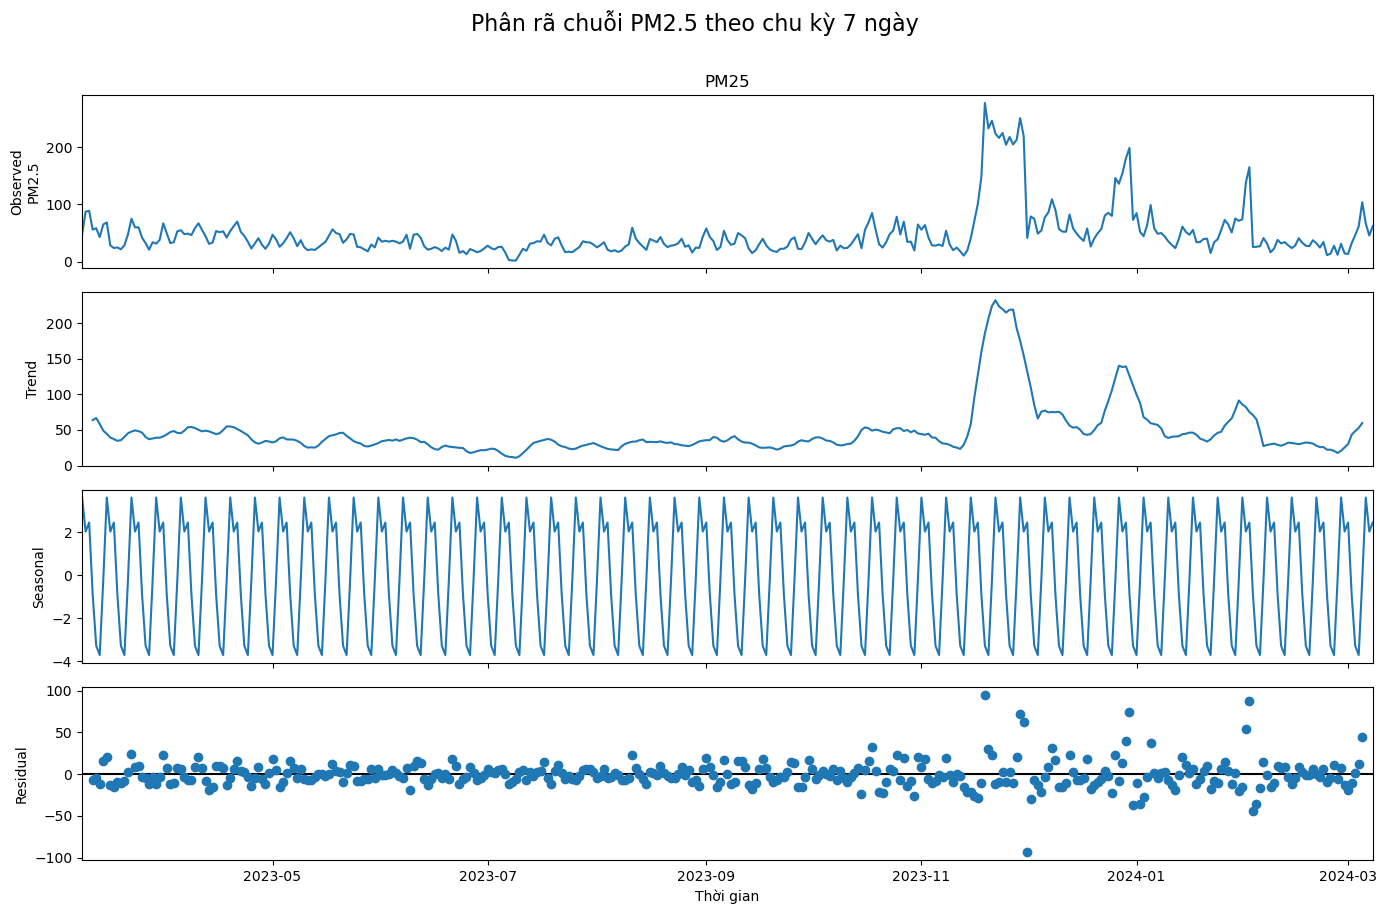

In [34]:
decomposition = seasonal_decompose(  # phan ra 1 chuoi thoi gian thanh cac thanh phan: trend, seasonal, residual
    daily_pm25.dropna(), # loai bo cac gia tri NaN truoc khi phan tich
    model='additive',   # tham so model='additive' de phan tich theo mo hinh cong, co nghia la cac thanh phan duoc cong lai de tao ra chuoi goc
    period=7  # chu ky
)


fig = decomposition.plot() # fig bien luu doi tuong Figure
fig.set_size_inches(14, 9)
fig.suptitle('Phân rã chuỗi PM2.5 theo chu kỳ 7 ngày', fontsize=16, y=1.01)

axes = fig.axes # danh sách biểu đồ con
axes[0].set_ylabel('Observed\nPM2.5')
axes[1].set_ylabel('Trend')
axes[2].set_ylabel('Seasonal')
axes[3].set_ylabel('Residual')
axes[3].set_xlabel('Thời gian')

plt.tight_layout()
plt.show()


Từ kết quả phân rã, có thể rút ra một số nhận xét:
1. PM2.5 có sự biến động khá lớn theo thời gian, đặc biệt xuất hiện những đợt tăng nồng độ mạnh vào khoảng tháng 11 và tháng 12/2023.
2. Thành phần Trend cho thấy xu hướng PM2.5 không ổn định trong toàn bộ giai đoạn nghiên cứu, có những thời điểm tăng mạnh và sau đó giảm xuống.
3. Thành phần Seasonal xuất hiện mô hình dao động lặp lại đều đặn theo chu kỳ 7 ngày. Tuy nhiên, biên độ mùa vụ khá nhỏ so với mức biến động của dữ liệu thực tế.
4. Thành phần Residual vẫn xuất hiện một số giá trị lệch lớn, cho thấy còn những biến động bất thường chưa được Trend và Seasonal giải thích.

## 2. Seasonal component theo ngày trong tuần

Giá trị dương cho biết ngày đó có PM2.5 cao hơn xu hướng chung; giá trị âm cho biết thấp hơn xu hướng.

Local Time
2023-03-08    3.623107
2023-03-09    2.037659
2023-03-10    2.457659
2023-03-11   -0.890485
2023-03-12   -3.285471
2023-03-13   -3.719524
2023-03-14   -0.222944
2023-03-15    3.623107
2023-03-16    2.037659
2023-03-17    2.457659
Freq: D, Name: seasonal, dtype: float64


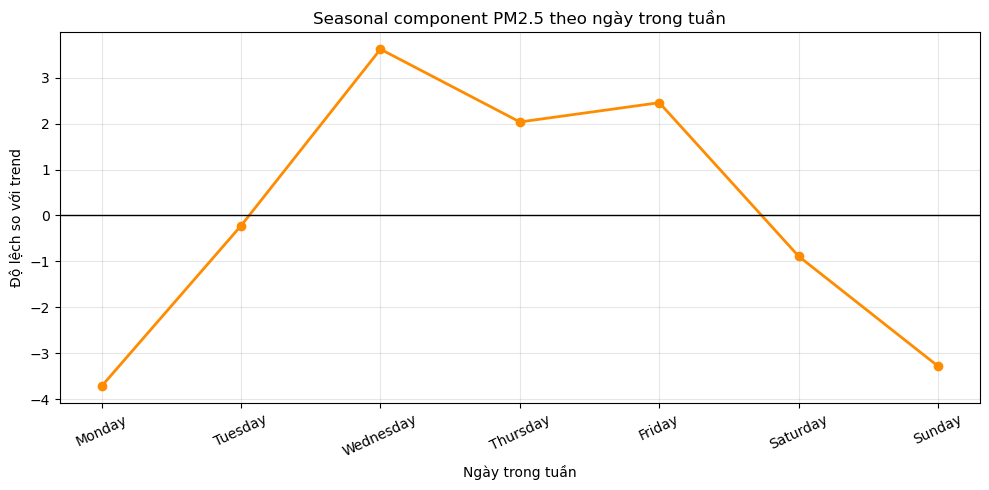

In [35]:
day_names = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
seasonal_by_day = decomposition.seasonal.groupby(
    decomposition.seasonal.index.dayofweek
).mean()
    
print (decomposition.seasonal.head(10))
plt.figure(figsize=(10, 5))
plt.plot(
    range(7),
    [seasonal_by_day.get(i, 0) for i in range(7)],
    marker='o',
    linewidth=2,
    color='darkorange'
)
plt.axhline(0, color='black', linewidth=1)
plt.xticks(range(7), day_names, rotation=25)
plt.title('Seasonal component PM2.5 theo ngày trong tuần')
plt.xlabel('Ngày trong tuần')
plt.ylabel('Độ lệch so với trend')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 3. Residual bất thường

Residual là phần PM2.5 không được giải thích bởi trend và seasonal. Giá trị residual cực đại hoặc cực tiểu có thể là đợt ô nhiễm đột biến.

5 residual cao nhất:
Local Time
2023-11-19    94.951900
2024-02-02    87.387341
2023-12-30    74.045485
2023-11-29    72.091179
2023-11-30    62.605199
Name: resid, dtype: float64

5 residual thấp nhất:
Local Time
2023-12-01   -93.529087
2024-02-03   -44.588086
2023-12-31   -36.452386
2024-01-02   -35.671342
2024-02-04   -35.643814
Name: resid, dtype: float64


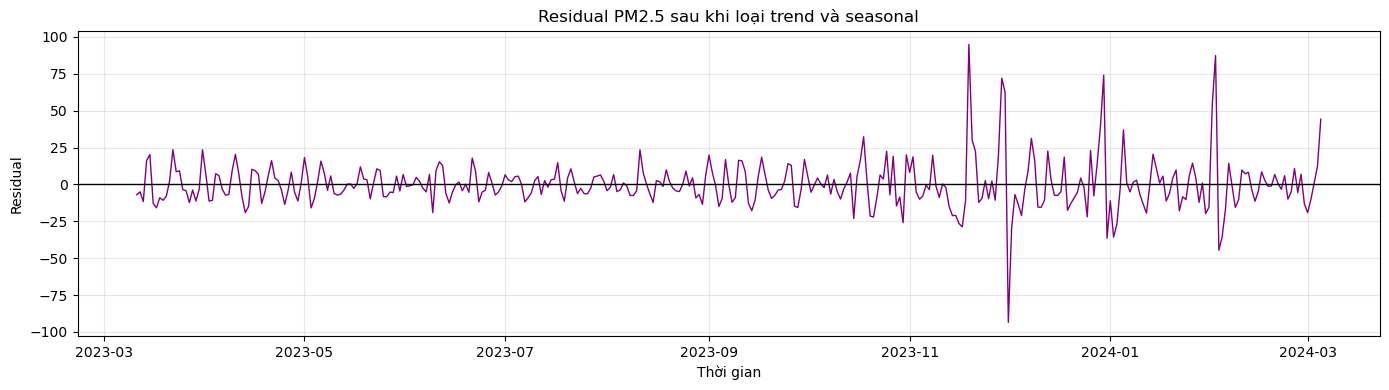

In [36]:
residual = decomposition.resid.dropna()

print('5 residual cao nhất:')
print(residual.nlargest(5))
print('\n5 residual thấp nhất:')
print(residual.nsmallest(5))

plt.figure(figsize=(14, 4))
plt.plot(residual, color='purple', linewidth=1)
plt.axhline(0, color='black', linewidth=1)
plt.title('Residual PM2.5 sau khi loại trend và seasonal')
plt.xlabel('Thời gian')
plt.ylabel('Residual')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()
